# Get steady state spectrum from bow shock

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.constants as const
import h5py

import matplotlib.colors as mcolors
import matplotlib.cm as cm

import flash_amr_tools

flash_output_dir = "/home/watanabe/Projects/meerkat_bowshocks/outputs"
fig_dir = "/home/watanabe/Projects/meerkat_bowshocks/figures"
data_dir = "/home/watanabe/Projects/meerkat_bowshocks/meerkat_nrfs/meerkat_nrfs/data/"

In [22]:
# simulation output file
sim_file = "BowShock_HarpISM/starISM_hdf5_plt_cnt_0001"

# parameters set in this file
mstar = 20 * u.M_sun
vstar = 30 * (u.km / u.s)
env_name = "ISM"
kappa_10 = 3e25 * (u.cm**2 / u.s)

Also read in stan off radius

In [23]:
with h5py.File(f"{data_dir}/standoff_radius.h5", "r") as f:

    mstar_grid = f["mstar_grid"][()] * u.Msun
    vstar_grid = f["vstar_grid"][()] * u.km / u.s

    R0_grid = f[env_name]["R0_grid"][()] * u.cm

mstar_idx = np.digitize(mstar, mstar_grid, right=True)
vstar_idx = np.digitize(vstar, vstar_grid, right=True)

R0 = R0_grid[mstar_idx, vstar_idx].to(u.pc)
print(f"Stand-off radius: {R0.to(u.pc):.3f}")

Stand-off radius: 1.294 pc


Read in steady state spectrum data

In [24]:
with h5py.File(f"{data_dir}/steady_state_spectrum_thr.h5", "r") as f:
    log10_R0_grid = f["log10_R0_grid"][()]
    log10_vel_grid = f["log10_vel_grid"][()]
    log10_kappa10_grid = f["log10_kappa10_grid"][()]
    log10_dens_grid = f["log10_dens_grid"][()]
    alpha_inj_grid = f["alpha_inj_grid"][()]
    log10_enratio_grid_full = f["log10_enratio_grid"][()]

log10_enratio_grid = log10_enratio_grid_full[:,np.digitize(np.log10(kappa_10.value), log10_kappa10_grid, right=True), np.digitize(np.log10(R0.value), log10_R0_grid, right=True),:,:]

# first interpolate the enratio grid
from scipy.interpolate import RegularGridInterpolator

f_log10enratio = RegularGridInterpolator((alpha_inj_grid, log10_vel_grid,log10_dens_grid), log10_enratio_grid)

initialise amrtools

In [25]:
blist, brefs, bns = flash_amr_tools.get_true_blocks(f"{flash_output_dir}/{sim_file}")

minimum position of the region of interest:  [-4.62851637e+19 -9.25703274e+19 -9.25703274e+19]
maximum position of the region of interest:  [1.38855491e+20 9.25703274e+19 9.25703274e+19]
Finding all leaf blocks in given region
512 512
Biggest block has refinement level: 4
Highest refinement level in simulation: 4
Highest refinement level in selected box: 4
Extending region to fit amr structure at level 4.
bnx, bny, bnz:  8.0 8.0 8.0
Block shape:  (8, 8, 8)
Total number of blocks including parent blocks: 512
Region extended to:	lower		upper
	x	-4.62851646e+19		+1.38855494e+20
	y	-9.25703293e+19		+9.25703293e+19
	z	-9.25703293e+19		+9.25703293e+19

Region center at:	+4.62851646e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+4.62851637e+19	+0.00000000e+00	+0.00000000e+00


extract relevant data

In [31]:
with h5py.File(f"{flash_output_dir}/{sim_file}", "r") as pf:
    shma_data = pf["shma"][()][blist]
    dens_data = pf["dens"][()][blist]
    vel_data = [pf["velx"][()][blist], pf["vely"][()][blist], pf["velz"][()][blist]] 
    encr_data = pf["encr"][()][blist]
    ref_lvl = pf["refine level"][()][blist]
    bbox = pf["bounding box"][()][blist]
    bsize = pf["block size"][()][blist]

low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]

extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

In [41]:
cell_size_data = np.zeros_like(dens_data)
cell_size = bsize / 8.0

cell_size_data = np.tile(cell_size[:,0], reps=(8,8,8)).reshape((bsize.shape[0], 8,8,8))

First compute injection index

-0.0


Text(0, 0.5, 'Injection Index $\\alpha_\\mathrm{inj}$')

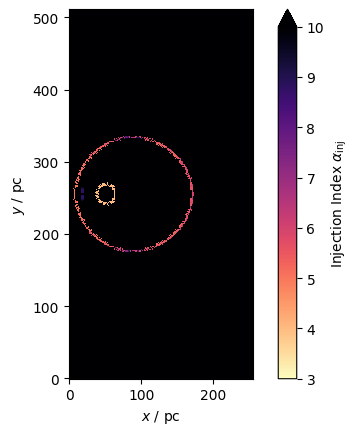

In [7]:
shma_cube = flash_amr_tools.get_cube(shma_data, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)
gam = 5/3

xs_cube = (gam + 1) * shma_cube**2 / (2 + (gam - 1) * shma_cube**2)
alpha_inj_cube = 3 * xs_cube / (xs_cube - 1)

print(np.min(alpha_inj_cube))

# force minimal and maximal values
alpha_inj_cube[alpha_inj_cube < 4] = 10
alpha_inj_cube[alpha_inj_cube >= 10] = 10

# %reset_selective -f "shma_cube"
# %reset_selective -f "xs_cube"

# plot
fig, ax = plt.subplots()
norm = mcolors.Normalize(vmin=3, vmax=10, clip=True)

im = ax.imshow(alpha_inj_cube[...,127].T, norm=norm, cmap=cm.magma_r, alpha=1.0, interpolation="none", origin="lower")

# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax, extend='max')
cb.ax.set_ylabel(r"Injection Index $\alpha_\mathrm{inj}$")

In [8]:
vel_mag_cube = np.linalg.norm(flash_amr_tools.get_vector_cube(vel_data, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns), axis=-1) * (u.cm / u.s)
dens_cube = flash_amr_tools.get_cube(dens_data, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

Compute the enratio

In [9]:
enratio_cube = 10.0**f_log10enratio((alpha_inj_cube, np.log10(vel_mag_cube.to_value(u.km/u.s)), np.log10(dens_cube))) * u.GeV
print(enratio_cube.min(), enratio_cube.max())

1.6118641551190245 GeV 15.416467486618918 GeV


Text(0, 0.5, '$(\\epsilon_\\mathrm{CR} / n_\\mathrm{CR}) / \\mathrm{GeV}$')

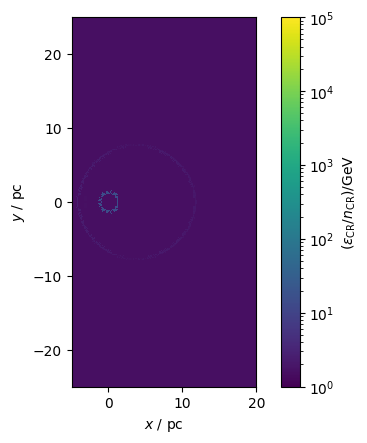

In [10]:
# # plot
fig, ax = plt.subplots()
norm = mcolors.LogNorm(vmin=1, vmax=1e5, clip=True)

im = ax.imshow(enratio_cube[...,128].to_value(u.GeV).T, norm=norm, cmap=cm.viridis, alpha=1.0, interpolation="none", extent=extent)

# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax)
cb.ax.set_ylabel("$(\epsilon_\mathrm{CR} / n_\mathrm{CR}) / \mathrm{GeV}$")

number density

In [11]:
encr_cube = flash_amr_tools.get_cube(encr_data * dens_data, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns) * (u.erg / u.cm**3)
ncr_cube = (encr_cube / enratio_cube).to(u.cm**-3)

print(ncr_cube.min(), ncr_cube.max())

7.181149250310741e-14 1 / cm3 1.7392586732450925e-10 1 / cm3


Text(0, 0.5, '$n_\\mathrm{CR}$ / cm$^{-3}$')

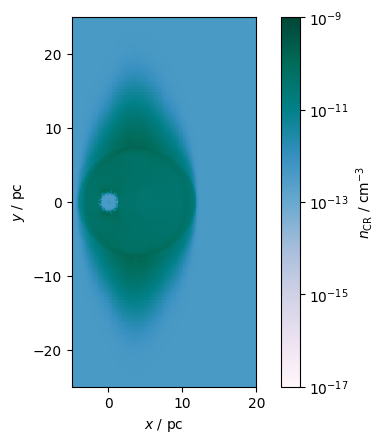

In [12]:
# # plot
fig, ax = plt.subplots()
norm = mcolors.LogNorm(vmin=1e-17, vmax=1e-9, clip=True)

im = ax.imshow(ncr_cube[...,128].value.T, norm=norm, cmap=cm.PuBuGn, alpha=1.0, interpolation="none", extent=extent)

# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax)
cb.ax.set_ylabel("$n_\mathrm{CR}$ / cm$^{-3}$")